# 02 Modelos


In [45]:
# Modulos y Datos

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Datos
bikes = pd.read_csv("https://raw.githubusercontent.com/robintux/Datasets4StackOverFlowQuestions/refs/heads/master/bikes.csv")
bikes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      731 non-null    int64  
 1   holiday     731 non-null    int64  
 2   weekday     731 non-null    int64  
 3   workingday  731 non-null    int64  
 4   weathersit  731 non-null    int64  
 5   temp        731 non-null    float64
 6   atemp       731 non-null    float64
 7   hum         731 non-null    float64
 8   windspeed   731 non-null    float64
 9   rentals     731 non-null    int64  
dtypes: float64(4), int64(6)
memory usage: 57.2 KB


### Primer Modelo de Regresion Lineal Multiple

In [2]:
# Primer paso :  Particionado del dataset
    # train : 80% de los datos
    # test : 20% de los datos

# Definamos a la variable dependiente
y = bikes.rentals

# Definamos a las variables independientes
X = bikes.drop(["rentals"], axis = 1)

# Creacion de los subconjuntos de train/test
X_train, X_test, y_train , y_test = train_test_split(X, y, train_size=0.8)

# Segundo Paso : Instanciamos la clase a modelar
model_base_bikes = LinearRegression()

# Ajustamos el modelo con el subconjunto de entrenamiento (X_train, y_train)
model_base_bikes.fit(X_train, y_train)
# Calculamos los parametros del modelo

# Tercer paso : Obtener indicadores de calidad
# Etapa1 : Usar el modelo (model_base_bikes) y los datos de testeo de las variables
# independientes para obtener pronosticos de la vaariable dependiente de test
y_test_forecast = model_base_bikes.predict(X_test)

# Etapa2 : Calcular un indicador de calidad
mape = metrics.mean_absolute_percentage_error(y_test, y_test_forecast)
mape

0.8688712720630118

In [ ]:
# Empaquetemos nuestro codigo en una funcion
def analisis_model_base ():
    """
    Documentacion
    """
    # Primer paso :  Particionado del dataset
    # train : 80% de los datos
    # test : 20% de los datos

    # Definamos a la variable dependiente
    y = bikes.rentals

    # Definamos a las variables independientes
    X = bikes.drop(["rentals"], axis = 1)

    # Creacion de los subconjuntos de train/test
    X_train, X_test, y_train , y_test = train_test_split(X, y, train_size=0.8)

    # Segundo Paso : Instanciamos la clase a modelar
    model_base_bikes = LinearRegression()

    # Ajustamos el modelo con el subconjunto de entrenamiento (X_train, y_train)
    model_base_bikes.fit(X_train, y_train)
    # Calculamos los parametros del modelo

    # Tercer paro : Obtener indicadores de calidad
    # Etapa1 : Usar el modelo (model_base_bikes) y los datos de testeo de las variables
    # independientes para obtener pronosticos de la vaariable dependiente de test
    y_test_forecast = model_base_bikes.predict(X_test)

    # Etapa2 : Calcular un indicador de calidad
    mape = metrics.mean_absolute_percentage_error(y_test, y_test_forecast)

    return mape


(0.0, 2.0)

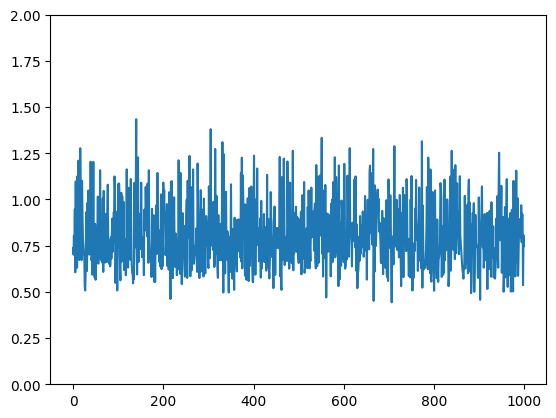

In [ ]:
# Hagamos 500 experimentos

# Lista para almacenar esos mape
lista_mape1 = []


for exp in range(1000):
    lista_mape1.append(analisis_model_base())

plt.plot(lista_mape1)
plt.ylim((0,2))

In [ ]:
# Cual es el MAPE representativo de todos estos 1000 experimentos ?
# Consideremos la media
sum(lista_mape1)/len(lista_mape1)

# ¿Esta media de los mape obtenidos es representativo?

0.8058768524537933

### 2do modelo : Regresion Lineal Multiple modificada

En esta parte se analiza la naturaleza de las variables independientes.

Observa que algunas variables tienen un comportamiento cualitativo:
- season
- holiday
- weekday
- workingday
- weathersit
Por ejemplo, season representa estaciones del año, no una magnitud numérica continua.

Por esa razón, el segundo modelo elimina estas cinco columnas.

In [3]:
# Columnas con las cuales se ajusto el primer modelo
X.columns

Index(['season', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp',
       'atemp', 'hum', 'windspeed'],
      dtype='object')

In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      731 non-null    int64  
 1   holiday     731 non-null    int64  
 2   weekday     731 non-null    int64  
 3   workingday  731 non-null    int64  
 4   weathersit  731 non-null    int64  
 5   temp        731 non-null    float64
 6   atemp       731 non-null    float64
 7   hum         731 non-null    float64
 8   windspeed   731 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 51.5 KB


In [ ]:
X.season.unique()
# La columna/variable season tiene mas un comportamiento cualitativo que un
# comportmiento cuantitativo

array([1, 2, 3, 4])

In [ ]:
X.holiday.unique()
# La columna/variable holiday tampoco tiene una naturaleza cuantitativa

array([0, 1])

In [ ]:
np.sort(X.weekday.unique())
# La columna/variable weekday tampoco tiene una naturaleza cuantitativa

array([0, 1, 2, 3, 4, 5, 6])

In [ ]:
X.workingday.unique()
# La columna/variable workingday tampoco tiene una naturaleza cuantitativa

array([0, 1])

In [ ]:
np.sort(X.weathersit.unique())
# La columna/variable workingday tampoco tiene una naturaleza cuantitativa

array([1, 2, 3])

In [ ]:
# La variable dependientes es la misma : y sigue siendo al columna rentals

# Modificamos el conjunto de variables independientes
X2 = bikes.drop(["rentals", "season", "holiday", "weekday", "workingday", "weathersit"], axis = 1)

# Particionamos nuestro nuevo conjunto de datos
X2_train, X2_test , y_train, y_test =  train_test_split(X2, y, train_size=0.8)

# Instanciamos la clase a modelar
model2_bikes = LinearRegression()

# Ajustamos el modelo con el subconjunto de entrenamiento
model2_bikes.fit(X2_train, y_train)

# Construimos pronosticos
y_test_forecast2 = model2_bikes.predict(X2_test)

# Calculamos un indicador de calidad
metrics.mean_absolute_percentage_error(y_test, y_test_forecast2)

1.0432260443345078

In [4]:
def analisis_model2():
    # Modificamos el conjunto de variables independientes
    X2 = bikes.drop(["rentals", "season", "holiday", "weekday", "workingday", "weathersit"], axis = 1)

    # Particionamos nuestro nuevo conjunto de datos
    X2_train, X2_test , y_train, y_test =  train_test_split(X2, y, train_size=0.8)

    # Instanciamos la clase a modelar
    model2_bikes = LinearRegression()

    # Ajustamos el modelo con el subconjunto de entrenamiento
    model2_bikes.fit(X2_train, y_train)

    # Construimos pronosticos
    y_test_forecast2 = model2_bikes.predict(X2_test)

    # Calculamos un indicador de calidad
    return metrics.mean_absolute_percentage_error(y_test, y_test_forecast2)


(0.0, 1.0)

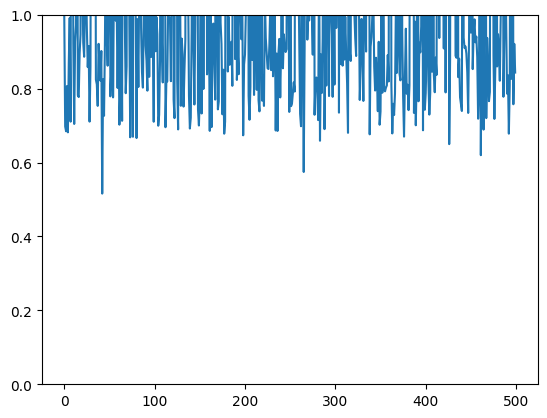

In [5]:
# Debemos desarrollar un numero determinado de experimentos para observar la
# estabilidad (inestabilidad de los resultados)

num_experimentos = 500
lista_mape2 = []

for exp in range(num_experimentos):
    lista_mape2.append(analisis_model2())

plt.plot(lista_mape2)
plt.ylim(0,1)

In [6]:
# Promedio de todos esos MAPE obtenidos en los experimentos
sum(lista_mape2)/len(lista_mape2)

1.1589443343082486

### 3er Modelo : Regresion Lineal Multiple + ONE_HOT encoding para las variables de naturaleza cualitativa

<Axes: xlabel='season'>

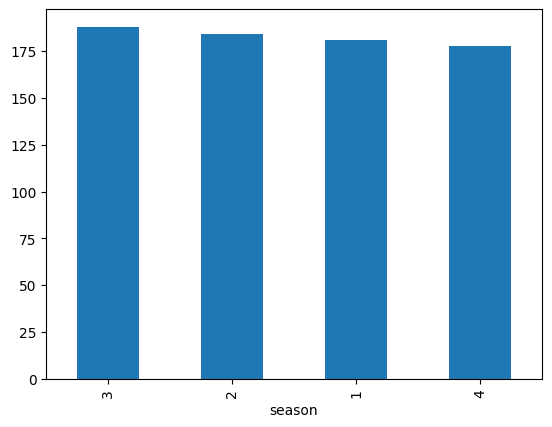

In [13]:
# Variable season
bikes.season.value_counts().plot(kind = "bar")

In [14]:
# Obtener la representacion de esta columna (unidimensional) y
# expresarlo en un espacio de 4D
pd.get_dummies(bikes.season, prefix= "season", dtype = "int")

,season_1,season_2,season_3,season_4
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,1,0,0,0
4,1,0,0,0
...,...,...,...,...
726,1,0,0,0
727,1,0,0,0
728,1,0,0,0
729,1,0,0,0


<Axes: xlabel='holiday'>

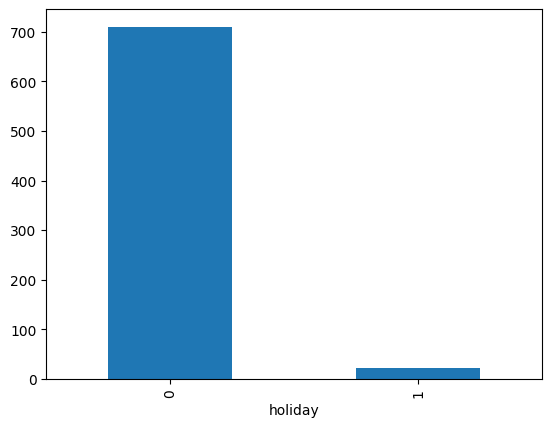

In [15]:
# La columna holiday
bikes.holiday.value_counts().plot(kind = "bar")

<Axes: xlabel='weekday'>

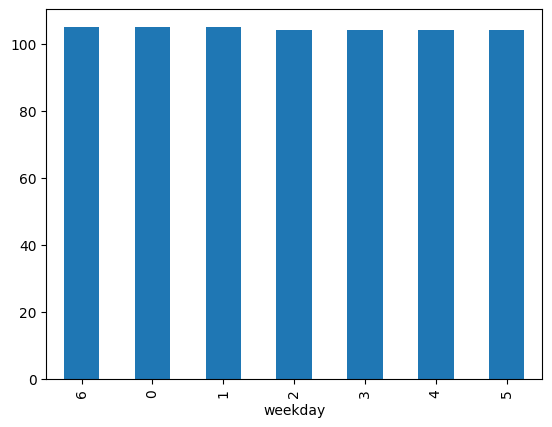

In [16]:
bikes.weekday.value_counts().plot(kind = "bar")

<Axes: xlabel='workingday'>

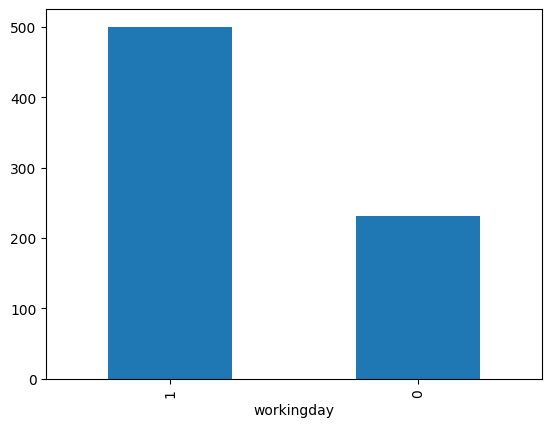

In [17]:
bikes.workingday.value_counts().plot(kind = "bar")

<Axes: xlabel='weathersit'>

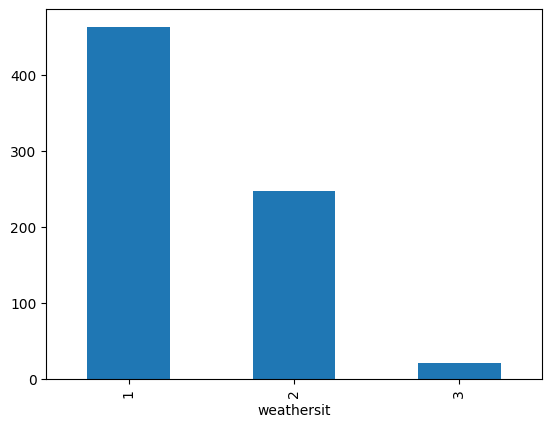

In [18]:
bikes.weathersit.value_counts().plot(kind = "bar")

In [19]:
# Columnas a considerar para realizar nuestro procedimiento de OHE
lista_columnas_OHE = ["workingday", "weekday", "season"]

# Empezamos con un dataframe en blanco
data_cuali = pd.DataFrame()

# Estructura repetitva : for
for col in lista_columnas_OHE:
    data_cuali = pd.concat([data_cuali, pd.get_dummies(bikes[col], prefix = col , dtype = "int")], axis = 1)

data_cuali

,workingday_0,workingday_1,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,season_1,season_2,season_3,season_4
0,1,0,0,0,0,0,0,0,1,1,0,0,0
1,1,0,1,0,0,0,0,0,0,1,0,0,0
2,0,1,0,1,0,0,0,0,0,1,0,0,0
3,0,1,0,0,1,0,0,0,0,1,0,0,0
4,0,1,0,0,0,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,0,1,0,0,0,0,1,0,0,1,0,0,0
727,0,1,0,0,0,0,0,1,0,1,0,0,0
728,1,0,0,0,0,0,0,0,1,1,0,0,0
729,1,0,1,0,0,0,0,0,0,1,0,0,0


In [20]:
bikes

,season,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,rentals
0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331
1,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131
2,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120
3,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108
4,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82
...,...,...,...,...,...,...,...,...,...,...
726,1,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247
727,1,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644
728,1,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159
729,1,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364


In [21]:
bikes2 = pd.concat([bikes.drop(["season", "holiday", "weekday", "workingday", "weathersit"], axis = 1), data_cuali], axis = 1)
bikes2

,temp,atemp,hum,windspeed,rentals,workingday_0,workingday_1,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,season_1,season_2,season_3,season_4
0,0.344167,0.363625,0.805833,0.160446,331,1,0,0,0,0,0,0,0,1,1,0,0,0
1,0.363478,0.353739,0.696087,0.248539,131,1,0,1,0,0,0,0,0,0,1,0,0,0
2,0.196364,0.189405,0.437273,0.248309,120,0,1,0,1,0,0,0,0,0,1,0,0,0
3,0.200000,0.212122,0.590435,0.160296,108,0,1,0,0,1,0,0,0,0,1,0,0,0
4,0.226957,0.229270,0.436957,0.186900,82,0,1,0,0,0,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,0.254167,0.226642,0.652917,0.350133,247,0,1,0,0,0,0,1,0,0,1,0,0,0
727,0.253333,0.255046,0.590000,0.155471,644,0,1,0,0,0,0,0,1,0,1,0,0,0
728,0.253333,0.242400,0.752917,0.124383,159,1,0,0,0,0,0,0,0,1,1,0,0,0
729,0.255833,0.231700,0.483333,0.350754,364,1,0,1,0,0,0,0,0,0,1,0,0,0


In [22]:
# Ajustemos nuestro tercer modelo
y = bikes2.rentals

# Definimos a las variables independientes
X3 = bikes2.drop(["rentals"], axis = 1)

# Particionamos los datos
X3_train, X3_test, y_train, y_test = train_test_split(X3, y, train_size=0.8)

# Instanciamos la clase a modelo
model3_bikes = LinearRegression()

# Ajustamos el modelo con el subconjunto de entrenamiento
model3_bikes.fit(X3_train, y_train)

# Construimos pronosticos
y_test_forecast3 = model3_bikes.predict(X3_test)

# Calculamos un indicador de calidad
metrics.mean_absolute_percentage_error(y_test, y_test_forecast3)



0.9394958813374444

## 4to modelo : Eliminar el intercepto

In [23]:
# Documentacion de LinearRegression
help(LinearRegression)

Help on class LinearRegression in module sklearn.linear_model._base:

class LinearRegression(sklearn.base.MultiOutputMixin, sklearn.base.RegressorMixin, LinearModel)
 |  LinearRegression(
 |      *,
 |      fit_intercept=True,
 |      copy_X=True,
 |      n_jobs=None,
 |      positive=False
 |  )
 |
 |  Ordinary least squares Linear Regression.
 |
 |  LinearRegression fits a linear model with coefficients w = (w1, ..., wp)
 |  to minimize the residual sum of squares between the observed targets in
 |  the dataset, and the targets predicted by the linear approximation.
 |
 |  Parameters
 |  ----------
 |  fit_intercept : bool, default=True
 |      Whether to calculate the intercept for this model. If set
 |      to False, no intercept will be used in calculations
 |      (i.e. data is expected to be centered).
 |
 |  copy_X : bool, default=True
 |      If True, X will be copied; else, it may be overwritten.
 |
 |  n_jobs : int, default=None
 |      The number of jobs to use for the comp

In [ ]:
# Repetir algun procesamiento de datos y considerar un modelo sin intercepto
model4_bikes = LinearRegression(fit_intercept=False)

In [44]:
# Primer paso :  Particionado del dataset
    # train : 80% de los datos
    # test : 20% de los datos

# Definamos a la variable dependiente
y = bikes.rentals

# Definamos a las variables independientes
X = bikes.drop(["rentals"], axis = 1)

# Creacion de los subconjuntos de train/test
X_train, X_test, y_train , y_test = train_test_split(X, y, train_size=0.8)

# Segundo Paso : Instanciamos la clase a modelar SIN intercepto
model4_bikes = LinearRegression(fit_intercept=False)

# Ajustamos el modelo con el subconjunto de entrenamiento (X_train, y_train)
model4_bikes.fit(X_train, y_train)
# Calculamos los parametros del modelo

# Tercer paso : Obtener indicadores de calidad
# Etapa1 : Usar el modelo (model_base_bikes) y los datos de testeo de las variables
# independientes para obtener pronosticos de la vaariable dependiente de test
y_test_forecast = model4_bikes.predict(X_test)

# Etapa2 : Calcular un indicador de calidad
mape = metrics.mean_absolute_percentage_error(y_test, y_test_forecast)
mape

0.7344932829507295

In [34]:
def analisis_model4 ():
    # Primer paso :  Particionado del dataset
      # train : 80% de los datos
      # test : 20% de los datos

  # Definamos a la variable dependiente
  y = bikes.rentals

  # Definamos a las variables independientes
  X = bikes.drop(["rentals"], axis = 1)

  # Creacion de los subconjuntos de train/test
  X_train, X_test, y_train , y_test = train_test_split(X, y, train_size=0.8)

  # Segundo Paso : Instanciamos la clase a modelar SIN intercepto
  model4_bikes = LinearRegression(fit_intercept=False)

  # Ajustamos el modelo con el subconjunto de entrenamiento (X_train, y_train)
  model4_bikes.fit(X_train, y_train)
  # Calculamos los parametros del modelo

  # Tercer paso : Obtener indicadores de calidad
  # Etapa1 : Usar el modelo (model_base_bikes) y los datos de testeo de las variables
  # independientes para obtener pronosticos de la vaariable dependiente de test
  y_test_forecast = model4_bikes.predict(X_test)

  # Etapa2 : Calcular un indicador de calidad
  mape = metrics.mean_absolute_percentage_error(y_test, y_test_forecast)
  return mape

(0.0, 2.0)

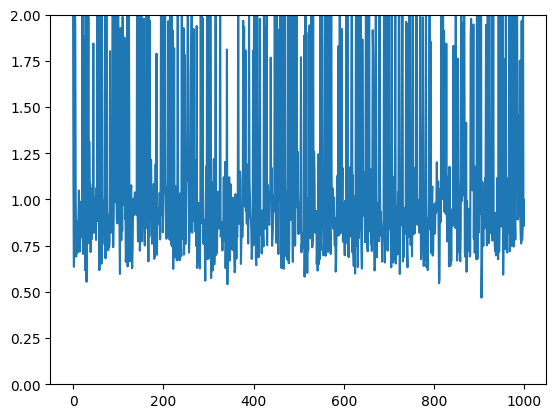

In [40]:
# Lista para almacenar esos mape
lista_mape4 = []


for exp in range(1000):
    lista_mape4.append(analisis_model4())

plt.plot(lista_mape4)
plt.ylim((0,2))

In [41]:
# Cual es el MAPE representativo de todos estos 1000 experimentos ?
# Consideremos la media
sum(lista_mape4)/len(lista_mape4)

1.1325642391966189